In [ ]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle

!chmod 600 ~/.kaggle/kaggle.json

### 1. Kaggle Dataset Download\nIn the next cell, we use the shell command `!` to interact with the system environment. We run the Kaggle CLI (`kaggle datasets download`) to download our target dataset directly from Kaggle using its unique dataset identifier.

### 1. Kaggle Dataset Download
In the next cell, we use the shell command `!` to interact with the system environment. We run the Kaggle CLI (`kaggle datasets download`) to download our target dataset directly from Kaggle using its unique dataset identifier.

In [ ]:
! kaggle datasets download -d srisyra02/ai-and-social-media-impact-student-health-and-grades

Dataset URL: https://www.kaggle.com/datasets/srisyra02/ai-and-social-media-impact-student-health-and-grades
License(s): CC0-1.0
100% 271k/271k [00:00<00:00, 101MB/s]



### 2. Unzipping the Dataset\nHere, we use the `!unzip` shell utility to extract all the files from our downloaded `.zip` archive so we can access the raw CSV data.

### 2. Unzipping the Dataset
Here, we use the `!unzip` shell utility to extract all the files from our downloaded `.zip` archive so we can access the raw CSV data.

In [ ]:
!unzip /content/ai-and-social-media-impact-student-health-and-grades.zip


Archive:  /content/ai-and-social-media-impact-student-health-and-grades.zip
  inflating: AI_SocialMedia_Student_Dataset.csv  


### 3. Loading Data with Pandas\nIn this cell, we import **Pandas** (`import pandas as pd`) and use the `pd.read_csv()` function to load our dataset into a tabular object called a **DataFrame** (`df`). We then use `.head()` to inspect the first 5 rows and subset a single column (`df['Gender']`) to check its values.

### 3. Loading Data with Pandas
In this cell, we import **Pandas** (`import pandas as pd`) and use the `pd.read_csv()` function to load our dataset into a tabular object called a **DataFrame** (`df`). We then use `.head()` to inspect the first 5 rows and subset a single column (`df['Gender']`) to check its values.

In [ ]:
import pandas as pd
df = pd.read_csv('/content/AI_SocialMedia_Student_Dataset.csv')
df.head()
df['Gender']

,Gender
0,Male
1,Non-binary
2,Male
3,Male
4,Non-binary
...,...
15995,Female
15996,Male
15997,Female
15998,Female


### 4. General Dataset Overview\nWe call `df.info()` to inspect our DataFrame's metadata. This function lists all the columns, their data types (numeric, categorical, etc.), and the count of non-null values in each column.

### 4. General Dataset Overview
We call `df.info()` to inspect our DataFrame's metadata. This function lists all the columns, their data types (numeric, categorical, etc.), and the count of non-null values in each column.

In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_ID                 16000 non-null  object 
 1   Age                        16000 non-null  int64  
 2   Gender                     16000 non-null  object 
 3   Education_Level            16000 non-null  object 
 4   Daily_Social_Media_Hours   16000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours  16000 non-null  float64
 6   Sleep_Hours                16000 non-null  float64
 7   Physical_Activity_Hours    16000 non-null  float64
 8   Mental_Health_Score        16000 non-null  float64
 9   Physical_Health_Score      16000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 1.2+ MB


### 5. Checking for Missing Data\nWe use `.isna()` and `.isnull()` to check for missing values. In the subsequent cells, we chain these with `.sum()` to find the total count of missing values per column, and check if any rows contain at least one missing value using `.isna().any(axis=1)`.

### 5. Checking for Missing Data
We use `.isna()` and `.isnull()` to check for missing values. In the subsequent cells, we chain these with `.sum()` to find the total count of missing values per column, and check if any rows contain at least one missing value using `.isna().any(axis=1)`.

In [ ]:
df.isna()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
15995,False,False,False,False,False,False,False,False,False,False
15996,False,False,False,False,False,False,False,False,False,False
15997,False,False,False,False,False,False,False,False,False,False
15998,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
15995,False,False,False,False,False,False,False,False,False,False
15996,False,False,False,False,False,False,False,False,False,False
15997,False,False,False,False,False,False,False,False,False,False
15998,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,0
Education_Level,0
Daily_Social_Media_Hours,0
Daily_AI_Tool_Usage_Hours,0
Sleep_Hours,0
Physical_Activity_Hours,0
Mental_Health_Score,0
Physical_Health_Score,0


In [ ]:
df.isna().any(axis=1)

,0
0,False
1,False
2,False
3,False
4,False
...,...
15995,False
15996,False
15997,False
15998,False


### 6. Removing Empty Rows\nWe call `df.dropna(how="all")` to drop rows from our dataset that contain exclusively null (`NaN`) values, ensuring our dataset is clean of empty records.

### 6. Removing Empty Rows
We call `df.dropna(how="all")` to drop rows from our dataset that contain exclusively null (`NaN`) values, ensuring our dataset is clean of empty records.

In [ ]:

df.dropna(how="all")

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04
...,...,...,...,...,...,...,...,...,...,...
15995,STU_15996,16,Female,High School,3.89,4.67,5.15,1.41,76.64,81.90
15996,STU_15997,14,Male,High School,4.42,3.24,5.57,1.52,77.50,96.36
15997,STU_15998,15,Female,High School,0.00,2.89,5.56,1.81,77.56,99.58
15998,STU_15999,20,Female,College,0.30,5.09,5.61,1.25,80.69,82.03


In [ ]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,0
Education_Level,0
Daily_Social_Media_Hours,0
Daily_AI_Tool_Usage_Hours,0
Sleep_Hours,0
Physical_Activity_Hours,0
Mental_Health_Score,0
Physical_Health_Score,0


### 7. Time and Periods in Pandas\nWe use `pd.period_range()` to demonstrate how to generate sequential monthly time periods (`freq="M"`) in Pandas, which is useful for setting up time-series indices.

### 7. Time and Periods in Pandas
We use `pd.period_range()` to demonstrate how to generate sequential monthly time periods (`freq="M"`) in Pandas, which is useful for setting up time-series indices.

In [ ]:
# Demonstration of datetime and period creation with valid columns or simulated data
pd.period_range("2024-01", periods=12, freq="M")

PeriodIndex(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
             '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12'],
            dtype='period[M]')

In [ ]:
# Since 'manufacturing_year' does not exist, let's work with the 'Age' column instead
df["age_copy"] = df["Age"].astype(int)
display(df[["Age", "age_copy"]].head())

,Age,age_copy
0,19,19
1,16,16
2,25,25
3,23,23
4,20,20


### 8. Grouping and Aggregating Data\nWe use the `.groupby()` function to group our data by `Physical_Activity_Hours`. We then select specific columns (`['Mental_Health_Score', 'Physical_Health_Score']`) and calculate their mean for each group, saving the result to a new DataFrame called `g`.

### 8. Grouping and Aggregating Data
We use the `.groupby()` function to group our data by `Physical_Activity_Hours`. We then select specific columns (`['Mental_Health_Score', 'Physical_Health_Score']`) and calculate their mean for each group, saving the result to a new DataFrame called `g`.

In [ ]:
# Display the columns actually available in the dataset to avoid KeyErrors
print("Available columns:", list(df.columns))

Available columns: ['Student_ID', 'Age', 'Gender', 'Education_Level', 'Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours', 'Sleep_Hours', 'Physical_Activity_Hours', 'Mental_Health_Score', 'Physical_Health_Score', 'age_copy']


In [ ]:
pd.set_option("display.max_rows",20)

In [ ]:
df.head()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,age_copy
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,19
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,16
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,25
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,23
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,20


In [ ]:
pd.describe_option("display.max_rows")

display.max_rows : int
    If max_rows is exceeded, switch to truncate view. Depending on
    `large_repr`, objects are either centrally truncated or printed as
    a summary view. 'None' value means unlimited.

    In case python/IPython is running in a terminal and `large_repr`
    equals 'truncate' this can be set to 0 and pandas will auto-detect
    the height of the terminal and print a truncated object which fits
    the screen height. The IPython notebook, IPython qtconsole, or
    IDLE do not run in a terminal and hence it is not possible to do
    correct auto-detection.
    [default: 60] [currently: 20]


In [ ]:
pd.get_option("display.max_rows")

20

In [ ]:
pd.set_option("display.width",1000)

In [ ]:
df.memory_usage(deep=True)

,0
Index,132
Student_ID,928000
Age,128000
Gender,867024
Education_Level,935413
Daily_Social_Media_Hours,128000
Daily_AI_Tool_Usage_Hours,128000
Sleep_Hours,128000
Physical_Activity_Hours,128000
Mental_Health_Score,128000


In [ ]:
g=df.groupby('Physical_Activity_Hours')[['Mental_Health_Score',
'Physical_Health_Score']].mean()

### 9. Descriptive Aggregation Statistics\nThese cells demonstrate various descriptive summary methods available on grouped Pandas objects:\n* `.size` to find the total elements\n* `.count()` to count valid non-null records\n* `.sum()`, `.mean()`, `.median()`, `.std()`, and `.var()` to evaluate basic statistics.

### 9. Descriptive Aggregation Statistics
These cells demonstrate various descriptive summary methods available on grouped Pandas objects:
* `.size` to find the total elements
* `.count()` to count valid non-null records
* `.sum()`, `.mean()`, `.median()`, `.std()`, and `.var()` to evaluate basic statistics.

In [ ]:
g

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.00,69.368198,82.476347
0.01,70.152000,82.664286
0.02,68.170909,83.472000
0.03,70.850690,84.563448
0.04,70.604167,84.693889
...,...,...
4.85,79.280000,99.110000
4.88,85.260000,96.660000
4.97,87.960000,99.890000


In [ ]:
g.size

924

In [ ]:
g.count()

,0
Mental_Health_Score,462
Physical_Health_Score,462


In [ ]:
g.sum()

,0
Mental_Health_Score,34569.630292
Physical_Health_Score,42400.616804


In [ ]:
g.mean()

,0
Mental_Health_Score,74.826040
Physical_Health_Score,91.776227


In [ ]:
g.median()

,0
Mental_Health_Score,74.444513
Physical_Health_Score,92.282272


In [ ]:
g.std()

,0
Mental_Health_Score,3.944913
Physical_Health_Score,4.812923


In [ ]:
g.var()

,0
Mental_Health_Score,15.562337
Physical_Health_Score,23.164226


In [ ]:
g.min()

,0
Mental_Health_Score,60.47000
Physical_Health_Score,79.86303


In [ ]:
g.max()

,0
Mental_Health_Score,87.96
Physical_Health_Score,99.90


In [ ]:
g.head(1)

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.0,69.368198,82.476347


In [ ]:
g.tail()

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
4.85,79.280000,99.110000
4.88,85.260000,96.660000
4.97,87.960000,99.890000
4.98,86.150000,97.050000
5.00,79.624444,97.645556


### 10. Advanced Aggregations and Custom Transformations\n* `g.agg()`: Customizes multiple statistical metrics (e.g., sum, mean, count) to run on our columns at once.\n* `g.apply(lambda x: ...)`: Applies a custom calculation or function element-wise across our grouped data structure.

### 10. Advanced Aggregations and Custom Transformations
* `g.agg()`: Customizes multiple statistical metrics (e.g., sum, mean, count) to run on our columns at once.
* `g.apply(lambda x: ...)`: Applies a custom calculation or function element-wise across our grouped data structure.

In [ ]:
g.iloc[0]

,0.0
Mental_Health_Score,69.368198
Physical_Health_Score,82.476347


In [ ]:
g.agg("sum")

,0
Mental_Health_Score,34569.630292
Physical_Health_Score,42400.616804


In [ ]:
g.agg(["sum","mean","count"])

,Mental_Health_Score,Physical_Health_Score
sum,34569.630292,42400.616804
mean,74.826040,91.776227
count,462.000000,462.000000


In [ ]:






































































































# Apply a standard lambda function to scale or format values, or simple custom function on our dataset group
g.apply(lambda x: x * 100)

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.00,6936.819836,8247.634677
0.01,7015.200000,8266.428571
0.02,6817.090909,8347.200000
0.03,7085.068966,8456.344828
0.04,7060.416667,8469.388889
...,...,...
4.85,7928.000000,9911.000000
4.88,8526.000000,9666.000000
4.97,8796.000000,9989.000000


In [ ]:
# Filtering rows in 'g' where Mental_Health_Score is greater than 75
filtered_g = g[g['Mental_Health_Score'] > 75]
display(filtered_g.head())

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.72,75.619487,87.371026
1.64,75.618043,87.986957
1.68,75.408511,91.391277
1.70,76.787778,92.662222
1.75,75.173448,89.674828


### Row Filtering Using Boolean Indexing

To filter rows in pandas based on actual column values, you use **boolean indexing**. This works by:
1. Creating a boolean Series (a series of `True` and `False` values) representing your condition.
2. Passing that boolean Series inside square brackets `df[...]` to subset the rows where the condition is `True`.

Let's filter your DataFrame `g` to show only the years where the average `driving_stress_score` was greater than `40`:

In [ ]:
# 1. Create a boolean mask based on Mental_Health_Score
mask = g['Mental_Health_Score'] > 75
print("Boolean Mask:")
display(mask.head())

# 2. Filter the DataFrame using the mask
filtered_g = g[mask]
print("\nFiltered DataFrame (Mental_Health_Score > 75):")
display(filtered_g.head())

Boolean Mask:


,Mental_Health_Score
Physical_Activity_Hours,
0.00,False
0.01,False
0.02,False
0.03,False
0.04,False



Filtered DataFrame (Mental_Health_Score > 75):


,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.72,75.619487,87.371026
1.64,75.618043,87.986957
1.68,75.408511,91.391277
1.70,76.787778,92.662222
1.75,75.173448,89.674828


### 11. Plotting Configuration and Libraries\nHere we load our visualization environment. We import **Matplotlib** (`matplotlib.pyplot as plt`), **Seaborn** (`sns`), and **Plotly** (`plotly.express as px`). We use `%matplotlib inline` to render figures inside this notebook and set a beautiful modern theme with `sns.set_theme()`.

### 11. Plotting Configuration and Libraries
Here we load our visualization environment. We import **Matplotlib** (`matplotlib.pyplot as plt`), **Seaborn** (`sns`), and **Plotly** (`plotly.express as px`). We use `%matplotlib inline` to render figures inside this notebook and set a beautiful modern theme with `sns.set_theme()`.

In [ ]:
g.mean()

,0
Mental_Health_Score,74.826040
Physical_Health_Score,91.776227


In [ ]:
# Let's check value counts of a valid categorical column in df, like 'Education_Level'
df["Education_Level"].value_counts()

,count
Education_Level,
High School,6083
University,5027
College,4890


In [ ]:
g.describe()

,Mental_Health_Score,Physical_Health_Score
count,462.000000,462.000000
mean,74.826040,91.776227
std,3.944913,4.812923
min,60.470000,79.863030
25%,72.091063,87.942365
50%,74.444513,92.282272
75%,76.804226,95.891538
max,87.960000,99.900000


In [ ]:
g.rank()

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.00,20.0,11.0
0.01,36.0,12.0
0.02,8.0,21.0
0.03,57.0,34.0
0.04,47.0,38.0
...,...,...
4.85,405.0,448.0
4.88,453.0,372.0
4.97,462.0,461.0


In [ ]:
g.cumsum()

,Mental_Health_Score,Physical_Health_Score
Physical_Activity_Hours,,
0.00,69.368198,82.476347
0.01,139.520198,165.140632
0.02,207.691107,248.612632
0.03,278.541797,333.176081
0.04,349.145964,417.869970
...,...,...
4.85,34230.635848,42009.371249
4.88,34315.895848,42106.031249
4.97,34403.855848,42205.921249


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_ID                 16000 non-null  object 
 1   Age                        16000 non-null  int64  
 2   Gender                     16000 non-null  object 
 3   Education_Level            16000 non-null  object 
 4   Daily_Social_Media_Hours   16000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours  16000 non-null  float64
 6   Sleep_Hours                16000 non-null  float64
 7   Physical_Activity_Hours    16000 non-null  float64
 8   Mental_Health_Score        16000 non-null  float64
 9   Physical_Health_Score      16000 non-null  float64
 10  age_copy                   16000 non-null  int64  
dtypes: float64(6), int64(2), object(3)
memory usage: 1.3+ MB


In [ ]:
# Display the first few rows of df to inspect the data structure properly
display(df.head())

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,age_copy
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,19
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,16
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,25
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,23
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,20


In [ ]:
from ast import increment_lineno
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
%matplotlib inline
plt.style.use("seaborn-v0_8")
sns.set_theme(style="whitegrid",palette="deep",font_scale=1.0)


### 12. Matplotlib Visualization Methods\nThese cells showcase core visualization plots in **Matplotlib**:\n* `ax.bar()`: Create bar charts representing categories.\n* `ax.scatter()`: Draw scatter plots to find correlations.\n* `ax.hist()`: Draw frequency distribution histograms.\n* `ax.boxplot()`: Draw box-and-whisker plots to inspect data distribution medians and outliers.

### 12. Matplotlib Visualization Methods
These cells showcase core visualization plots in **Matplotlib**:
* `ax.bar()`: Create bar charts representing categories.
* `ax.scatter()`: Draw scatter plots to find correlations.
* `ax.hist()`: Draw frequency distribution histograms.
* `ax.boxplot()`: Draw box-and-whisker plots to inspect data distribution medians and outliers.

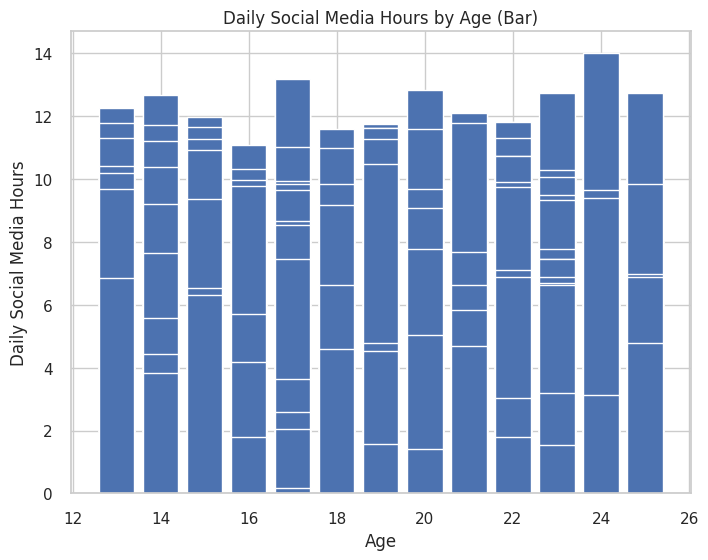

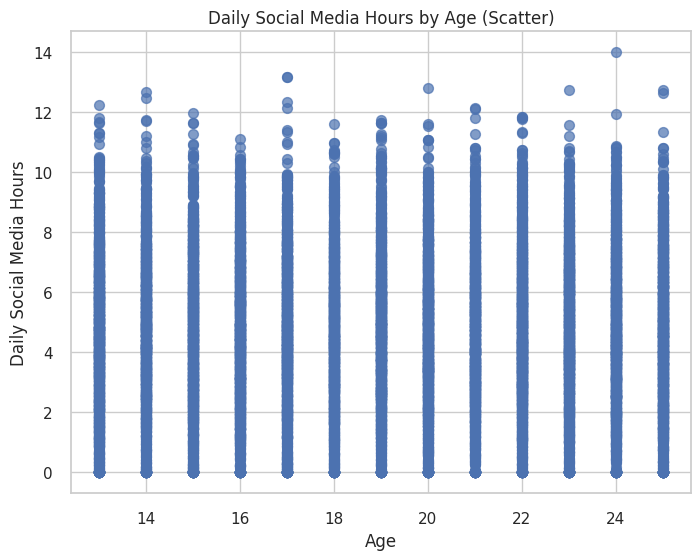

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
ax.bar('Age', 'Daily_Social_Media_Hours', data=df.sort_values('Age'))

ax.set_xlabel('Age')
ax.set_ylabel('Daily Social Media Hours')
ax.set_title('Daily Social Media Hours by Age (Bar)')
plt.show()

fig, ax2 = plt.subplots(figsize=(8, 6), dpi=100)
ax2.scatter('Age', 'Daily_Social_Media_Hours', data=df.sort_values('Age'), marker='o', s=50, alpha=0.7)
ax2.set_xlabel('Age')
ax2.set_ylabel('Daily Social Media Hours')
ax2.set_title('Daily Social Media Hours by Age (Scatter)')
plt.show()

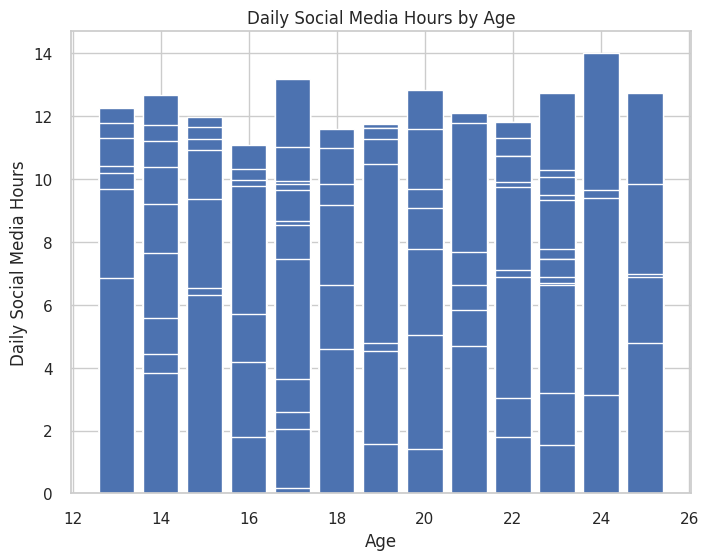

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
ax.bar('Age', 'Daily_Social_Media_Hours', data=df.sort_values('Age'))
ax.set_xlabel('Age')
ax.set_ylabel('Daily Social Media Hours')
ax.set_title('Daily Social Media Hours by Age')
plt.show()

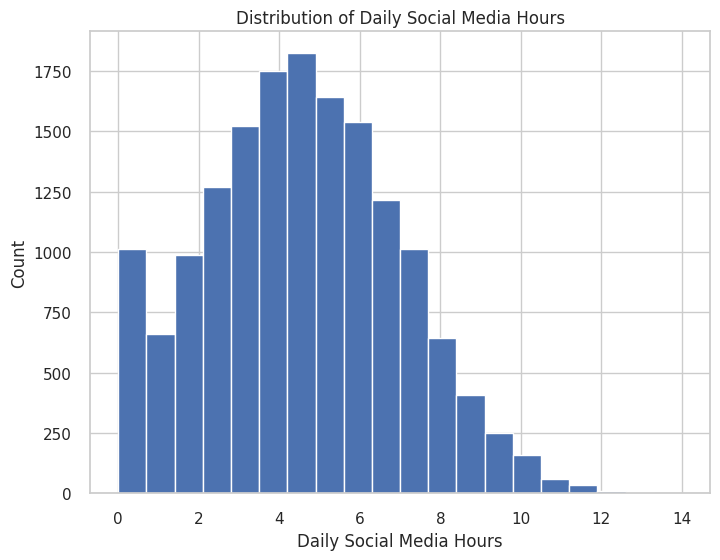

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
ax.set_title("Distribution of Daily Social Media Hours")
ax.set_xlabel("Daily Social Media Hours")
ax.set_ylabel("Count")
ax.hist('Daily_Social_Media_Hours', bins=20, data=df, edgecolor='white')
plt.show()

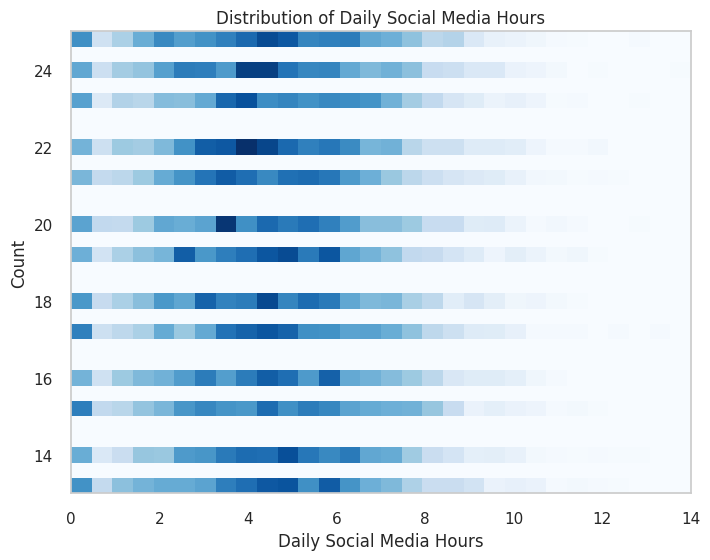

In [ ]:
fig,ax = plt.subplots(figsize=(8, 6), dpi=100)
ax.set_title("Distribution of Daily Social Media Hours")
ax.set_xlabel("Daily Social Media Hours")
ax.set_ylabel("Count")
ax.hist2d('Daily_Social_Media_Hours','Age' ,bins=30,cmap="Blues",data=df)
plt.show()


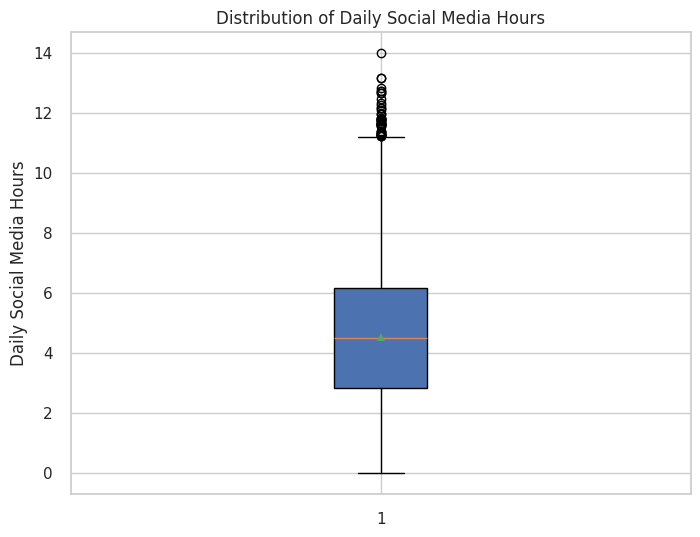

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
ax.set_title("Distribution of Daily Social Media Hours")
ax.set_ylabel("Daily Social Media Hours")
ax.boxplot(df['Daily_Social_Media_Hours'], vert=True, patch_artist=True, showmeans=True)
plt.show()

In [ ]:
df.head()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,age_copy
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,19
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,16
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,25
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,23
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,20


In [ ]:
aaaa

NameError: name 'aaaa' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')
ax.scatter(df['Mental_Health_Score'],df['Physical_Health_Score'],s=10,alpha=0.5)
plt.show()


In [ ]:
fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')
ax.scatter(df['Mental_Health_Score'],df['Physical_Health_Score'],s=10,alpha=0.5)
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_xticks(range(0,101,10))
ax.set_yticks(range(0,101,10))
ax.set_yscale("log")
ax.invert_xaxis()
ax.invert_yaxis()
plt.show()

In [ ]:
fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')
ax.scatter(df['Mental_Health_Score'],df['Physical_Health_Score'],s=10,alpha=0.5)
ax.grid(True,linestyle="--",color="gray",alpha=0.5)
ax.set_facecolor("lightgray")
ax.set_aspect("equal")

plt.show()

In [ ]:
fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')
ax.scatter(df['Mental_Health_Score'],df['Physical_Health_Score'],s=10,alpha=0.7,color="virdis")
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_xticks(range(0,101,10))
ax.set_yticks(range(0,101,10))
ax.text(3, 4, 'Student', style='italic', fontsize=30, color='green')
ax.axhline(y=10,color="yellow",linestyle=":")
ax.axvline(x=10,color="red",linstyle=":")
plt.show()


In [ ]:
fig,ax=plt.subplots(figsize=(12,8),dpi=100)
ax.set_title("Mental_health_Score")
ax.set_xlabel('Age')
ax.set_ylabel('Physical_Activity_Hours')
ax.violinplot(df['Physical_Activity_Hours'],showmedians=True,color='')
plt.show()

In [ ]:
fig,ax=plt.subplots(figsize=(12,8),dpi=100)
ax.set_title('Physical_Activity_Score vs Age')

In [ ]:
# Group the data to get the count of students per education level
education_counts = df['Education_Level'].value_counts()

# Create a clean pie chart
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)

# Plot pie chart
ax.pie(
    education_counts,
    labels=education_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')[0:3],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

ax.set_title('Distribution of Students by Education Level', fontsize=16, fontweight='bold')
plt.show()

### 1. Histogram (hist)
Visualizing the distribution of `Sleep_Hours` among students.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
ax.hist(df['Sleep_Hours'], bins=15, color='#F6E2E9', edgecolor='#DE7272')
ax.set_title('Distribution of Sleep Hours')
ax.set_xlabel('Sleep Hours')
ax.set_ylabel('Frequency')
plt.show()

### 2. 2D Histogram (hist2d)
Showing the joint distribution density between `Daily_Social_Media_Hours` and `Mental_Health_Score`.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
h = ax.hist2d(df['Daily_Social_Media_Hours'], df['Mental_Health_Score'], bins=30, cmap='viridis')
ax.set_title('2D Histogram: Social Media vs Mental Health')
ax.set_xlabel('Daily Social Media Hours')
ax.set_ylabel('Mental Health Score')
fig.colorbar(h[3], ax=ax, label='Count')
plt.show()

### 3. Scatter Plot (scatter)
Plotting `Sleep_Hours` against `Physical_Health_Score`.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
ax.scatter(df['Sleep_Hours'], df['Physical_Health_Score'], alpha=0.3, s=8, color='#DE7272')
ax.set_title('Sleep Hours vs Physical Health Score')
ax.set_xlabel('Sleep Hours')
ax.set_ylabel('Physical Health Score')
plt.show()

### 4. Bar Plot (bar)
Displaying the average `Daily_AI_Tool_Usage_Hours` by `Education_Level`.

In [ ]:
ai_usage_edu = df.groupby('Education_Level')['Daily_AI_Tool_Usage_Hours'].mean()
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
ax.bar(ai_usage_edu.index, ai_usage_edu.values, color=['#FF9999','#66B2FF','#99FF99'], edgecolor='gray')
ax.set_title('Average Daily AI Tool Usage by Education Level')
ax.set_xlabel('Education Level')
ax.set_ylabel('Average AI Usage (Hours)')
fig.tight_layout()

fig.suptitle('Average Daily AI Tool Usage by Education Level', fontsize=16, fontweight='bold')
plt.show()

### 5. Horizontal Bar Plot (barh)
Showing the average `Mental_Health_Score` across different genders.

In [ ]:
mental_gender = df.groupby('Gender')['Mental_Health_Score'].mean()
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
ax.barh(mental_gender.index, mental_gender.values, color='teal', height=0.5)
fig.subplots_adjust(left=0.3)

ax.set_title('Average Mental Health Score by Gender')
ax.set_xlabel('Average Mental Health Score')
ax.set_ylabel('Gender')
plt.show()

In [ ]:
fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')
ax.scatter(df['Mental_Health_Score'],df['Physical_Health_Score'],s=10,alpha=0.5)
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_xticks(range(0,101,10))
ax.set_yticks(range(0,101,10))
ax.set_yscale("log")
ax.invert_xaxis()
ax.invert_yaxis()
plt.xticks(rotation=45)
plt.show()

### 6. Box Plot (boxplot)
Showing the distribution of `Mental_Health_Score` grouped by `Education_Level`.

In [ ]:
levels = df['Education_Level'].unique()
data_to_plot = [df[df['Education_Level'] == level]['Mental_Health_Score'] for level in levels]

fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
ax.boxplot(data_to_plot, labels=levels, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='blue'),
           medianprops=dict(color='red'))
ax.set_title('Mental Health Score Distribution by Education Level')
ax.set_xlabel('Education Level')
ax.set_ylabel('Mental Health Score')
plt.show()

### 7. Violin Plot (violinplot)
Comparing the distribution of `Sleep_Hours` grouped by `Education_Level`.

In [ ]:
sleep_data = [df[df['Education_Level'] == level]['Sleep_Hours'].values for level in levels]

fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
parts = ax.violinplot(sleep_data, showmeans=False, showmedians=True, showextrema=True)

# Color customization
for pc in parts['bodies']:
    pc.set_facecolor('orange')
    pc.set_edgecolor('black')
    pc.set_alpha(0.6)

ax.set_xticks(range(1, len(levels) + 1))
ax.set_xticklabels(levels)
ax.set_title('Sleep Hours Distribution by Education Level')
ax.set_xlabel('Education Level')
ax.set_ylabel('Sleep Hours')
plt.show()

### 9. Error Bar (errorbar)
Plotting the average `Mental_Health_Score` by `Age` with standard deviation error bars.

In [ ]:
age_stats = df.groupby('Age')['Mental_Health_Score'].agg(['mean', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
ax.errorbar(
    age_stats['Age'],
    age_stats['mean'],
    yerr=age_stats['std'],
    fmt='-o',
    color='crimson',
    ecolor='gray',
    elinewidth=1.5,
    capsize=3
)
ax.set_title('Average Mental Health Score by Age with Standard Deviation Error Bars')
ax.set_xlabel('Age')
ax.set_ylabel('Mental Health Score')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')

# Capture the returns from hist2d; the 4th element (index 3) is the image mappable
h2d = ax.hist2d(df['Mental_Health_Score'], df['Physical_Health_Score'], bins=30, cmap='Blues')

# Pass the mappable explicitly to the colorbar creator
fig.colorbar(h2d[3], ax=ax, label='Count')
twin_ax=ax.twinx()
twin_ax2=ax.twiny()

plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')
ax.set_xlabel('Mental_Health_Score')
ax.set_ylabel('Physical_Health_Score')

# Capture the returns from hist2d; the 4th element (index 3) is the image mappable
h2d = ax.hist2d(df['Mental_Health_Score'], df['Physical_Health_Score'], bins=30, cmap='Blues')

# Pass the mappable explicitly to the colorbar creator
fig.colorbar(h2d[3], ax=ax, label='Count')
twin_ax=ax.twinx()
twin_ax2=ax.twiny()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(True)
plt.cm.viridis
plt.get_cmap('viridis')
plt.show()

In [ ]:

fig,ax=plt.subplots(figsize=(10,8),dpi=100)
ax.set_title('Mental_Health_Score vs Physical_Health_Score')

ax.hist(df['Mental_Health_Score'],bins=10,alpha=0.5)
plt.style.available
plt.rcParams["font.size"]=24

plt.show()

In [ ]:
df.plot(kind="line",x="Student_ID",y="Mental_Health_Score",figsize=(10,5))

In [ ]:
df['Daily_AI_Tool_Usage_Hours'].plot.bar()

In [ ]:
df['Physical_Activity_Hours'].plot.barh()

In [ ]:
df.plot.box()

In [ ]:
df.plot.hist(bins=20,alpha=0.5)

In [ ]:
df.plot.kde()

In [ ]:
df.plot.density()

In [ ]:
df.plot.area(stacked=True)

In [ ]:
df.plot.scatter(x="Age",y="Sleep_Hours",cmap="viridis",s=50)

In [ ]:
df["Education_Level"].value_counts().plot.pie(autopct="%1.1f%%")

In [ ]:
df.plot.hexbin(x='Sleep_Hours',y='Mental_Health_Score',gridsize=15)

In [ ]:
df['Sleep_Hours'].plot()

In [ ]:
df.plot(subplots=True, layout=(3, 3), figsize=(12, 9), sharex=False)


In [ ]:
df.plot(secondary_y="Sleep_Hours")

In [ ]:
df.hist(column='Mental_Health_Score', by='Education_Level', bins=15, figsize=(10, 6))

In [ ]:
df.boxplot(column='Daily_Social_Media_Hours',by='Education_Level')

In [ ]:
pd.plotting.scatter_matrix(df, diagonal="kde", figsize=(10, 10))

In [ ]:
pd.plotting.autocorrelation_plot(df['Daily_Social_Media_Hours'])

In [ ]:
pd.plotting.lag_plot(df['Daily_AI_Tool_Usage_Hours'])

In [ ]:
# Select numeric columns + class column to avoid TypeError on non-numeric columns like Student_ID and Gender
numeric_cols = df.select_dtypes(include='number').columns.tolist()
plot_df = df.sample(100, random_state=42)[numeric_cols + ['Education_Level']]

pd.plotting.andrews_curves(plot_df, class_column='Education_Level')

In [ ]:
pd.plotting.parallel_coordinates(plot_df, class_column='Education_Level')

In [ ]:
pd.plotting.bootstrap_plot(df['Age'])

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Radviz requires a DataFrame with multiple numerical features and a class column
numeric_cols = df.select_dtypes(include='number').columns.tolist()

# Sample a subset of the DataFrame to keep the Radviz plot clean and readable
plot_df = df.sample(100, random_state=42)[numeric_cols + ['Education_Level']]

# Plotting Radviz correctly
plt.subplots(figsize=(8, 8), dpi=100)
pd.plotting.radviz(plot_df, class_column='Education_Level', colormap='viridis')
plt.title('Radviz Plot of Student Dataset by Education Level')
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6), dpi=100)
sns.scatterplot(data=df, x="Age", y="Daily_AI_Tool_Usage_Hours", hue="Education_Level", palette="viridis")
plt.title('Daily AI Tool Usage Hours vs Age by Education Level')
plt.show()

In [ ]:
sns.lineplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age by Education Level')
plt.show()


In [ ]:
sns.relplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", col="Gender", palette="viridis")
plt.suptitle('Sleep Hours vs Age by Education Level and Gender')
plt.show()

In [ ]:
sns.histplot(data=df, x="Age", hue="Education_Level", multiple="stack", palette="viridis")
plt.title('Age Distribution by Education Level')
plt.show()

In [ ]:
sns.kdeplot(data=df, x="Age", hue="Education_Level", fill=True, palette="viridis")
plt.title('Age Distribution by Education Level')
plt.show()

In [ ]:
sns.ecdfplot(data=df, x="Age", hue="Education_Level", palette="viridis")
plt.title('Age Distribution by Education Level')
plt.show()

### 13. Advanced Multi-Variate Seaborn Visuals\nWe leverage Seaborn functions for deep statistical plots:\n* `sns.scatterplot()` and `sns.lineplot()`: Track trends with optional categorization overlays using `hue`.\n* `sns.relplot()`: Create subplot grids split across a categorical dimension.\n* `sns.kdeplot()` & `sns.ecdfplot()`: Display smoothed probability density curves and cumulative steps.

### 13. Advanced Multi-Variate Seaborn Visuals
We leverage Seaborn functions for deep statistical plots:
* `sns.scatterplot()` and `sns.lineplot()`: Track trends with optional categorization overlays using `hue`.
* `sns.relplot()`: Create subplot grids split across a categorical dimension.
* `sns.kdeplot()` & `sns.ecdfplot()`: Display smoothed probability density curves and cumulative steps.

In [ ]:
sns.rugplot(data=df, x="Mental_Health_Score", hue="Education_Level", palette="viridis")
plt.title('Age Distribution by Education Level')
plt.show()

In [ ]:
sns.displot(data=df, x="Age", hue="Education_Level", multiple="stack", palette="viridis")
plt.title('Age Distribution by Education Level')
plt.show()

In [ ]:
sns.jointplot(data=df, x="Age", y="Mental_Health_Score", hue="Education_Level", palette="viridis")
plt.title('Age vs Mental Health Score by Education Level')
plt.show()

In [ ]:
sns.pairplot(df,hue='cat',palette='viridis',diag_kind="kde")
plt.title('Education')
plt.show()

In [ ]:
sns.barplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()


In [ ]:





sns.countplot(data=df, x="Physical_Activity_Hours", hue="Education_Level", palette="viridis")
plt.title('Physical Activity Hours Distribution by Education Level')
plt.show()

In [ ]:
sns.boxplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#

In [ ]:
sns.violinplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()

In [ ]:
sns.stripplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#

In [ ]:
sns.swarmplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#

In [ ]:
sns.boxenplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#

In [ ]:
sns.pointplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#

In [ ]:
sns.catplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()
#
#

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="viridis")
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
sns.clustermap(df.corr(numeric_only=True), annot=True, cmap="viridis")
plt.title('Clustered Correlation Heatmap')
plt.show()

### 14. Interactive Plotly Express Graphics\nWe use **Plotly Express** (`px`) to create interactive, dynamic graphics that scale and show details on hover. Plots demonstrated include `px.line`, `px.bar`, `px.scatter_3d`, `px.pie`, `px.sunburst`, and `px.imshow`.

### 14. Interactive Plotly Express Graphics
We use **Plotly Express** (`px`) to create interactive, dynamic graphics that scale and show details on hover. Plots demonstrated include `px.line`, `px.bar`, `px.scatter_3d`, `px.pie`, `px.sunburst`, and `px.imshow`.

In [ ]:
sns.regplot(data=df, x="Age", y="Sleep_Hours", color="red")
plt.title('Sleep Hours vs Age')
plt.show()

In [ ]:
sns.lmplot(data=df, x="Age", y="Sleep_Hours", hue="Education_Level", palette="viridis")
plt.title('Sleep Hours vs Age')
plt.show()

In [ ]:
sns.residplot(data=df, x="Age", y="Sleep_Hours", color="red")
plt.title('Residual Plot')
plt.show()

#plotly


In [ ]:
import plotly.express as px
fig = px.line(df, x="Age", y="Sleep_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.bar(df, x="Age", y="Sleep_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.scatter(df, x="Age", y="Physical_Activity_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.histogram(df, x="Age", y="Physical_Activity_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.box(df, x="Age", y="Physical_Activity_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.violin(df, x="Age", y="Physical_Activity_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.pie(df, names="Education_Level", values="Physical_Activity_Hours", color="Education_Level")
fig.show()

In [ ]:
fig = px.sunburst(df, path=['Age','Education_Level'], values='Physical_Activity_Hours', color='Education_Level')
fig.show()

In [ ]:
fig = px.treemap(df, path=['Age','Education_Level'], values='Physical_Activity_Hours', color='Education_Level')
fig.show()

In [ ]:
fig=px.scatter_3d(df,x='Age',y='Sleep_Hours',z='Physical_Activity_Hours',color='Education_Level')
fig.show()

In [ ]:
fig = px.scatter_matrix(df, dimensions=['Age', 'Sleep_Hours', 'Physical_Activity_Hours'], color='Education_Level')
fig.show()

In [ ]:
fig = px.scatter_matrix(df, dimensions=['Age', 'Sleep_Hours', 'Mental_Health_Score'], color='Education_Level')
fig.show()

In [ ]:
fig=px.density_heatmap(df,x='Age',y='Sleep_Hours',z='Physical_Activity_Hours',color='Education_Level')
fig.show()

TypeError: density_heatmap() got an unexpected keyword argument 'color'

In [ ]:
fig=px.density_contour(df,x='Age',y='Sleep_Hours',z='Physical_Activity_Hours',color='Education_Level')


fig.show()

In [ ]:
fig=px.choropleth(df,locations='Age',color='Sleep_Hours',hover_name='Education_Level')
fig.show()

In [ ]:
fig=px.scatter_geo(df,locations='Age',color='Sleep_Hours',hover_name='Education_Level')
fig.show()

In [ ]:
# Group to get meaningful average parameters per category for polar representation
polar_df = df.groupby('Education_Level')[['Age', 'Sleep_Hours', 'Physical_Activity_Hours']].mean().reset_index()
fig = px.line_polar(polar_df, r='Sleep_Hours', theta='Education_Level', color='Education_Level', line_close=True)
fig.show()

In [ ]:
# Calculate numerical correlation matrix to render with imshow
corr_matrix = df.select_dtypes(include='number').corr()
fig = px.imshow(corr_matrix, text_auto=True, color_continuous_scale='RdBu_r')
fig.show()

In [ ]:
fig=px.area(df,x='Age',y='Sleep_Hours',color='Education_Level')
fig.show()

In [ ]:
# Group counts by category so the funnel receives a structured tabular frame
funnel_df = df.groupby('Education_Level').size().reset_index(name='Student_Count')
fig = px.funnel(funnel_df, x='Student_Count', y='Education_Level', color='Education_Level')
fig.show()

In [ ]:
fig=px.timeline(df,x_start='Age',x_end='Sleep_Hours',y='Education_Level')
fig.show()

In [ ]:
import plotly.express as px

# Create a copy of the dataframe and map categorical 'Education_Level' to numeric values
plot_df = df.copy()
plot_df['Education_Level_Code'] = plot_df['Education_Level'].astype('category').cat.codes

# Parallel coordinates requires numerical columns
numeric_cols = df.select_dtypes(include='number').columns.tolist()

fig = px.parallel_coordinates(
    plot_df,
    dimensions=numeric_cols,
    color='Education_Level_Code',
    color_continuous_scale=px.colors.diverging.Tealrose,
    title='Parallel Coordinates Plot (Colored by Education Level)'
)
fig.show()

In [ ]:
import plotly.express as px

# Create a copy and map the categorical Education_Level to numeric codes for color representation
plot_df = df.copy()
plot_df['Education_Level_Code'] = plot_df['Education_Level'].astype('category').cat.codes

fig = px.parallel_categories(
    plot_df,
    color='Education_Level_Code',
    color_continuous_scale=px.colors.diverging.Tealrose,
    title='Parallel Categories Plot (Colored by Education Level)'
)
fig.show()

ValueError: Could not interpret value `Daily_AI_Usa` for `y`. An entry with this name does not appear in `data`.